# Assignment 5: Comparing representations across two layers of a rotated MNIST network
Audrey and Kevin

Every MNIST image is rotated by a random angle between 0° and 360°, and we keep each image's angle. We train a small MLP (784 → 256 → 64 → 10) to name the digit, then compare hidden layer 1 (256 units) with hidden layer 2 (64 units). Linear method: PCA. Nonlinear method: t-SNE. We also compare tuning curves and RDMs.

In [2]:
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt
from torchvision import datasets
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.stats import spearmanr

torch.manual_seed(0); np.random.seed(0)
train = datasets.MNIST('data', train=True, download=True)
test = datasets.MNIST('data', train=False, download=True)

100%|██████████| 9.91M/9.91M [00:00<00:00, 12.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 387kB/s]
100%|██████████| 1.65M/1.65M [00:04<00:00, 387kB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.27MB/s]


In [5]:
def rotate(images, seed):
    g = torch.Generator().manual_seed(seed)
    angle = torch.rand(len(images), generator=g) * 360
    t, zero = torch.deg2rad(angle), torch.zeros(len(images))
    theta = torch.stack([torch.stack([t.cos(), -t.sin(), zero], 1),
                         torch.stack([t.sin(), t.cos(), zero], 1)], 1)
    x = images.float().unsqueeze(1) / 255
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, align_corners=False), angle.numpy()

In [39]:
import torch
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
import math
import random

class RotatedMNIST(Dataset):
    def __init__(self, base_dataset, min_digit: int, max_digit: int, min_rotation_deg: float, max_rotation_deg: float):
        self.base_dataset = base_dataset # the original MNIST dataset
        self.min_rotation_deg = min_rotation_deg
        self.max_rotation_deg = max_rotation_deg

        # Filter dataset using max_digit:
        valid_indices = torch.where((base_dataset.targets >= min_digit) & (base_dataset.targets <= max_digit))[0]
        self.indices = valid_indices.tolist()

    def __len__(self):
        # Return the length of the filtered dataset, not the whole dataset:
        return len(self.indices)

    def __getitem__(self, idx):
        # Map the requested index to the actual index in the dataset:
        real_idx = self.indices[idx]

        # Retrieve the base image tensor and digit label:
        img_tensor, digit_label = self.base_dataset[real_idx]

        # Generate a random angle (0 to max_rotation parameter value)
        angle_deg = random.uniform(self.min_rotation_deg, self.max_rotation_deg)
        angle_rad = math.radians(angle_deg)

        # Rotate the image tensor
        img_rotated = TF.rotate(img_tensor, angle_deg, fill=0)

        # Convert continuous radian angle into a 2-value tensor (Sin and Cos)
        # $$$ Not using currently, but may consider if it improves accuracy
        #sin_cos_target = torch.tensor([math.sin(angle_rad), math.cos(angle_rad)], dtype=torch.float32)

        return img_rotated, digit_label, angle_rad, angle_deg

In [43]:
train_data = RotatedMNIST(
        base_dataset=train, 
        min_digit=0,
        max_digit=9,
        min_rotation_deg=0,
        max_rotation_deg=360
)

test_data = RotatedMNIST(
        base_dataset=train, 
        min_digit=0,
        max_digit=9,
        min_rotation_deg=0,
        max_rotation_deg=360
)

In [44]:
train_data

In [6]:
net = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(),
                    nn.Linear(256, 64), nn.ReLU(), nn.Linear(64, 10))
opt = torch.optim.Adam(net.parameters(), lr=1e-3)

In [9]:
for epoch in range(20):
    X_train, _ = rotate(train.data, epoch + 1)
    for idx in torch.randperm(len(X_train)).split(128):
        opt.zero_grad(); F.cross_entropy(net(X_train[idx]), train.targets[idx]).backward(); opt.step()

In [10]:
X, angle = rotate(test.data[:2000], 100); y = test.targets[:2000].numpy()
with torch.no_grad():
    print('test accuracy:', (net(X).argmax(1).numpy() == y).mean())
    h1 = net[:3](X).numpy()
    h2 = net[:5](X).numpy()
layers = {'Layer 1 (256 units)': h1, 'Layer 2 (64 units)': h2}
angle_bin = (angle // 30).astype(int)

test accuracy: 0.936


In [ ]:
trial = rotate(train.data, 1)

AttributeError: 'tuple' object has no attribute 'shape'

In [24]:
# 2 x 60k
trials = trial[0][:5]
trials

tensor([[[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]]],


        [[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]]],


        [[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]]],


        [[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
    

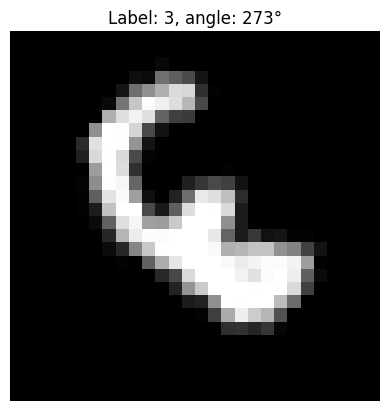

In [36]:
images, angles = trial          # rotate() returns (images, angles)
plt.imshow(images[10].squeeze(), cmap='gray')   # (1, 28, 28) -> (28, 28)
plt.title(f"Label: {train.targets[10].item()}, angle: {angles[0]:.0f}°")
plt.axis('off')
plt.show()


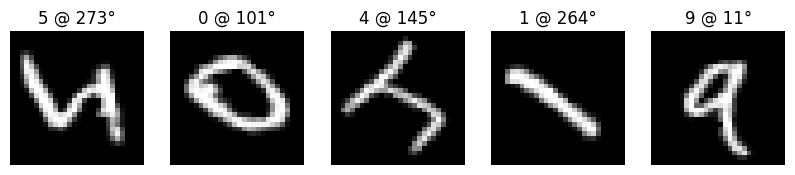

In [33]:
fig, ax = plt.subplots(1, 5, figsize=(10, 2))
for i in range(5):
    ax[i].imshow(images[i].squeeze(), cmap='gray')
    ax[i].set_title(f"{train.targets[i].item()} @ {angles[i]:.0f}°")
    ax[i].axis('off')
plt.show()


## Linear (PCA) and nonlinear (t-SNE) views of each layer

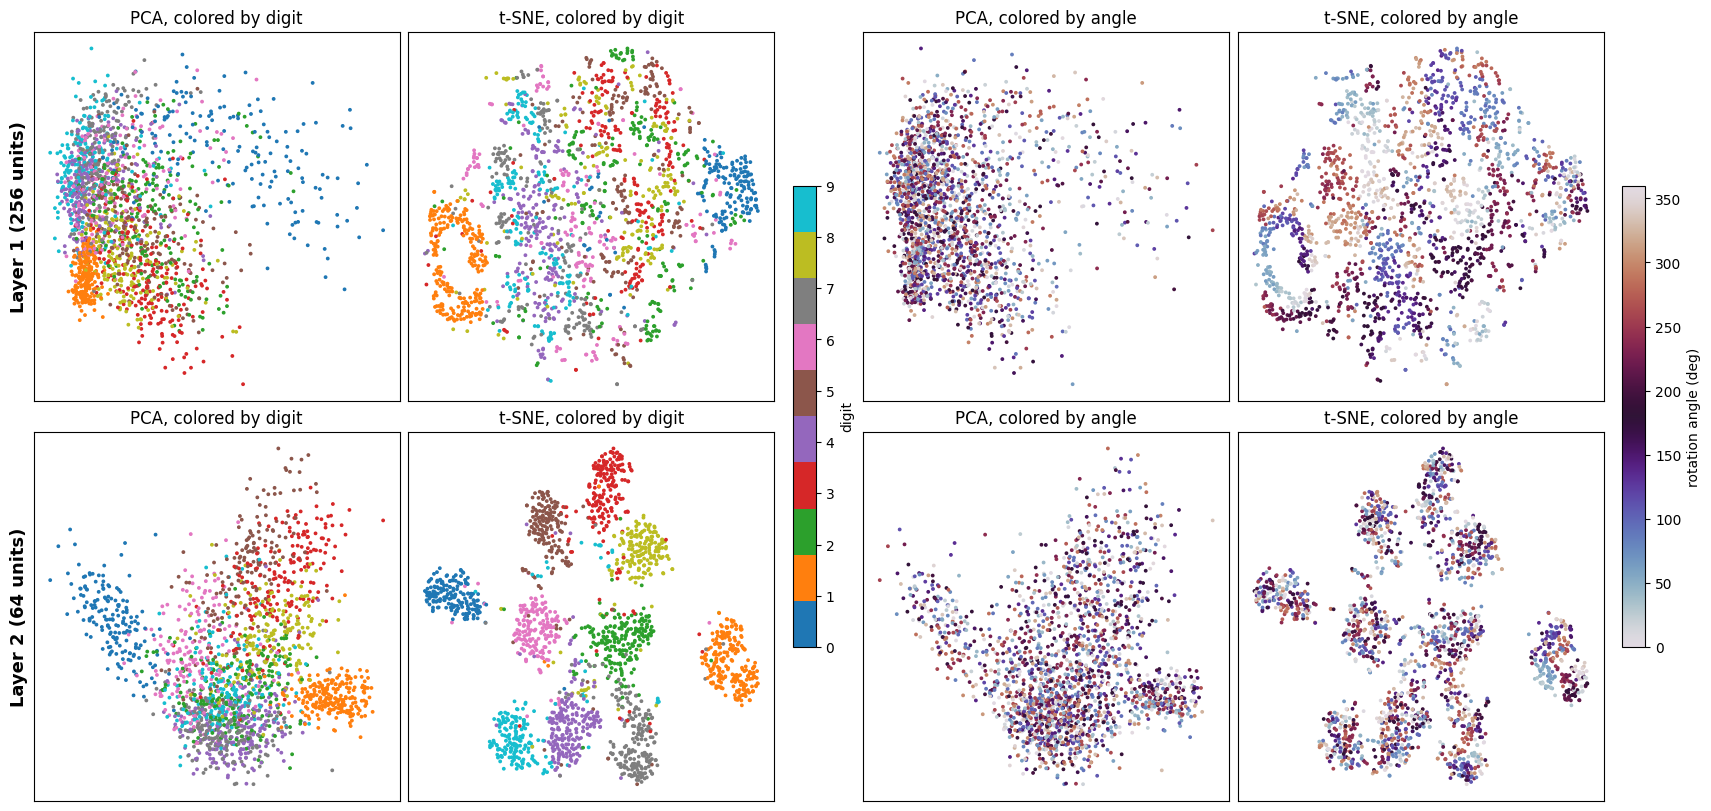

In [11]:
fig, ax = plt.subplots(2, 4, figsize=(17, 8), layout='constrained')
for r, (name, a) in enumerate(layers.items()):
    for c, (emb, method) in enumerate([(PCA(2).fit_transform(a), 'PCA'),
                                       (TSNE(2, random_state=0, init='pca').fit_transform(a), 't-SNE')]):
        s1 = ax[r, c].scatter(*emb.T, c=y, cmap='tab10', s=3)
        s2 = ax[r, c + 2].scatter(*emb.T, c=angle, cmap='twilight', vmin=0, vmax=360, s=3)
        ax[r, c].set(title=f'{method}, colored by digit', xticks=[], yticks=[])
        ax[r, c + 2].set(title=f'{method}, colored by angle', xticks=[], yticks=[])
    ax[r, 0].set_ylabel(name, fontsize=13, fontweight='bold')
fig.colorbar(s1, ax=ax[:, 1], label='digit', shrink=0.6)
fig.colorbar(s2, ax=ax[:, 3], label='rotation angle (deg)', shrink=0.6)
plt.show()

## Tuning curves for digit and rotation angle

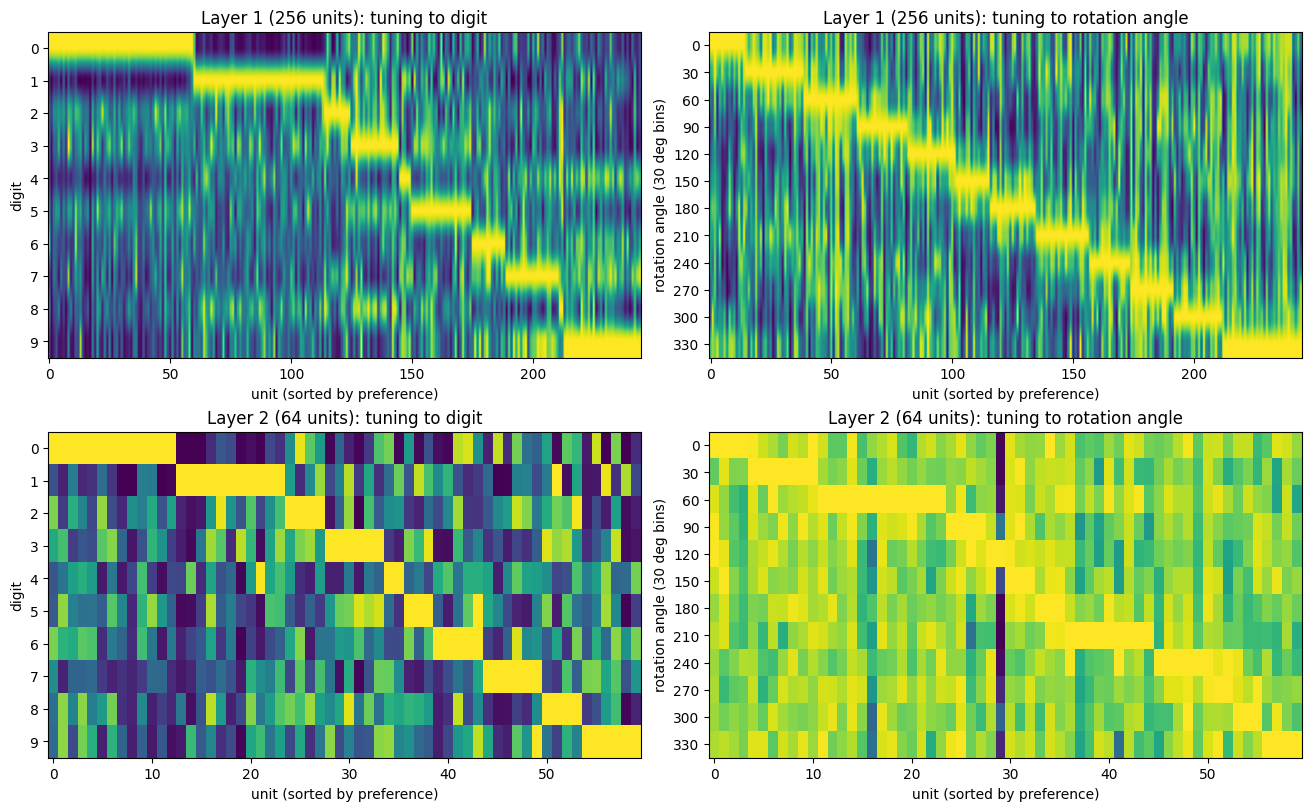

Layer 1 (256 units) {'active units': 245.0, 'digit selectivity': 0.445, 'angle selectivity': 0.327, 'variance explained by digit': 0.177, 'variance explained by angle': 0.077}
Layer 2 (64 units) {'active units': 60.0, 'digit selectivity': 0.436, 'angle selectivity': 0.106, 'variance explained by digit': 0.52, 'variance explained by angle': 0.016}


In [3]:
def tuning(a, labels):
    m = np.array([a[labels == k].mean(0) for k in np.unique(labels)])
    act = m.max(0) > 1e-6
    m = m[:, act]
    best, rest = m.max(0), (m.sum(0) - m.max(0)) / (len(m) - 1)
    explained = m.var(0) / a[:, act].var(0)
    return m, ((best - rest) / (best + rest)).mean(), explained.mean()

fig, ax = plt.subplots(2, 2, figsize=(13, 8), layout='constrained')
stats = {}
for r, (name, a) in enumerate(layers.items()):
    md, sel_d, var_d = tuning(a, y)
    ma, sel_a, var_a = tuning(a, angle_bin)
    for c, (m, label, ticks) in enumerate([(md, 'digit', range(10)), (ma, 'rotation angle (30 deg bins)', range(12))]):
        m = m[:, np.argsort(m.argmax(0))]
        ax[r, c].imshow(m / m.max(0), aspect='auto', cmap='viridis')
        ax[r, c].set(title=f'{name}: tuning to {label.split(" (")[0]}', xlabel='unit (sorted by preference)', ylabel=label, yticks=ticks)
    ax[r, 1].set_yticklabels([f'{30 * k}' for k in range(12)])
    stats[name] = {'active units': md.shape[1], 'digit selectivity': sel_d, 'angle selectivity': sel_a,
                   'variance explained by digit': var_d, 'variance explained by angle': var_a}
plt.show()
for name, s in stats.items():
    print(name, {k: round(float(v), 3) for k, v in s.items()})

## RDMs (600 test images, sorted by digit, then angle)

Pixels                 digit model rho = 0.075   angle model rho = 0.051


Layer 1 (256 units)    digit model rho = 0.231   angle model rho = 0.085
Layer 2 (64 units)     digit model rho = 0.430   angle model rho = 0.002


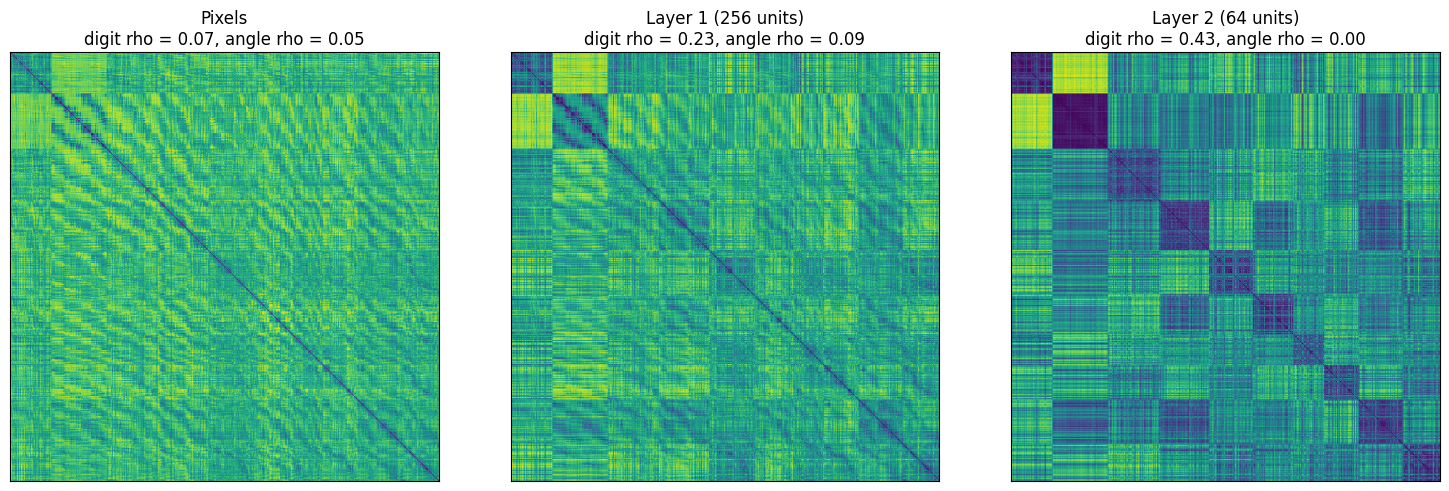

Pixels vs Layer 1 (256 units): rho = 0.720
Pixels vs Layer 2 (64 units): rho = 0.269
Layer 1 (256 units) vs Layer 2 (64 units): rho = 0.616
Layer 1 (256 units) PCs for 90% variance: 62
Layer 2 (64 units) PCs for 90% variance: 9


In [4]:
sub = np.random.choice(len(y), 600, replace=False)
sub = sub[np.lexsort((angle[sub], y[sub]))]
iu = np.triu_indices(len(sub), 1)
digit_model = (y[sub][:, None] != y[sub][None, :]).astype(float)
d = np.abs(angle[sub][:, None] - angle[sub][None, :])
angle_model = np.minimum(d, 360 - d)

def rdm(a):
    return 1 - np.corrcoef(a)

rdms = {'Pixels': rdm(X.flatten(1).numpy()[sub])}
rdms.update({name: rdm(a[sub]) for name, a in layers.items()})
fig, ax = plt.subplots(1, 3, figsize=(15, 4.8), layout='constrained')
for i, (name, R) in enumerate(rdms.items()):
    rho_d = spearmanr(R[iu], digit_model[iu])[0]
    rho_a = spearmanr(R[iu], angle_model[iu])[0]
    ax[i].imshow(R, cmap='viridis')
    ax[i].set(title=f'{name}\ndigit rho = {rho_d:.2f}, angle rho = {rho_a:.2f}', xticks=[], yticks=[])
    print(f'{name:22s} digit model rho = {rho_d:.3f}   angle model rho = {rho_a:.3f}')
plt.show()
names = list(rdms)
for i in range(3):
    for j in range(i + 1, 3):
        print(f'{names[i]} vs {names[j]}: rho = {spearmanr(rdms[names[i]][iu], rdms[names[j]][iu])[0]:.3f}')
for name, a in layers.items():
    print(name, 'PCs for 90% variance:', np.searchsorted(np.cumsum(PCA().fit(a).explained_variance_ratio_), 0.9) + 1)

## What changed from layer 1 to layer 2?
- **Rotation gets thrown away.** Layer 1 units are tuned to rotation angle, and each one prefers a narrow range of angles (angle selectivity 0.33). Layer 2 units are mostly flat across angle (0.11). Angle explains 7.7% of a layer 1 unit's variance but only 1.6% in layer 2, and the RDM's match to the angle model drops from 0.09 to 0.00.
- **Digit becomes the main structure.** Digit explains 52% of a layer 2 unit's variance, up from 18% in layer 1. The RDM matches the digit category model better (rho 0.23 to 0.43), and t-SNE splits layer 2 into clean digit clusters.
- **Single units don't get sharper.** Digit selectivity barely changes (0.45 vs 0.44). The change comes from units ignoring rotation, not from units becoming better digit detectors.
- **Compression:** layer 2 needs 9 PCs for 90% of the variance, compared with 62 for layer 1.
- **Linear vs nonlinear:** PCA only partly separates digits in either layer, while t-SNE shows clear clusters in layer 2. Much of the digit structure is nonlinear, so 2 linear dimensions miss it.
- **Overall:** the network applies a nonlinear (ReLU) transformation that removes a nuisance variable (rotation) and keeps the variable it was trained on (digit). The geometry moves step by step away from the pixels (RDM similarity with pixels: 0.72 for layer 1, 0.27 for layer 2).
- **Compared with unrotated MNIST:** accuracy drops from 95.9% to 90.1%, and both layers match the digit model less well (0.23 and 0.43, vs 0.41 and 0.49 before), because rotation scrambles the pixels.